Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Training shape: (2000, 64, 64, 3)
Test shape: (500, 64, 64, 3)


C:\Users\EiLi1\AppData\Local\Temp\ipykernel_22072\3570989769.py:80: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.5900 - loss: 1.2682 - val_accuracy: 0.7750 - val_loss: 0.7246
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8517 - loss: 0.4740 - val_accuracy: 0.7800 - val_loss: 0.6522
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9172 - loss: 0.3052 - val_accuracy: 0.8300 - val_loss: 0.6254
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9489 - loss: 0.2020 - val_accuracy: 0.8000 - val_loss: 0.6595
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9733 - loss: 0.1332 - val_accuracy: 0.8150 - val_loss: 0.6531
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7780 - loss: 0.7605
Test accuracy: 77.80%


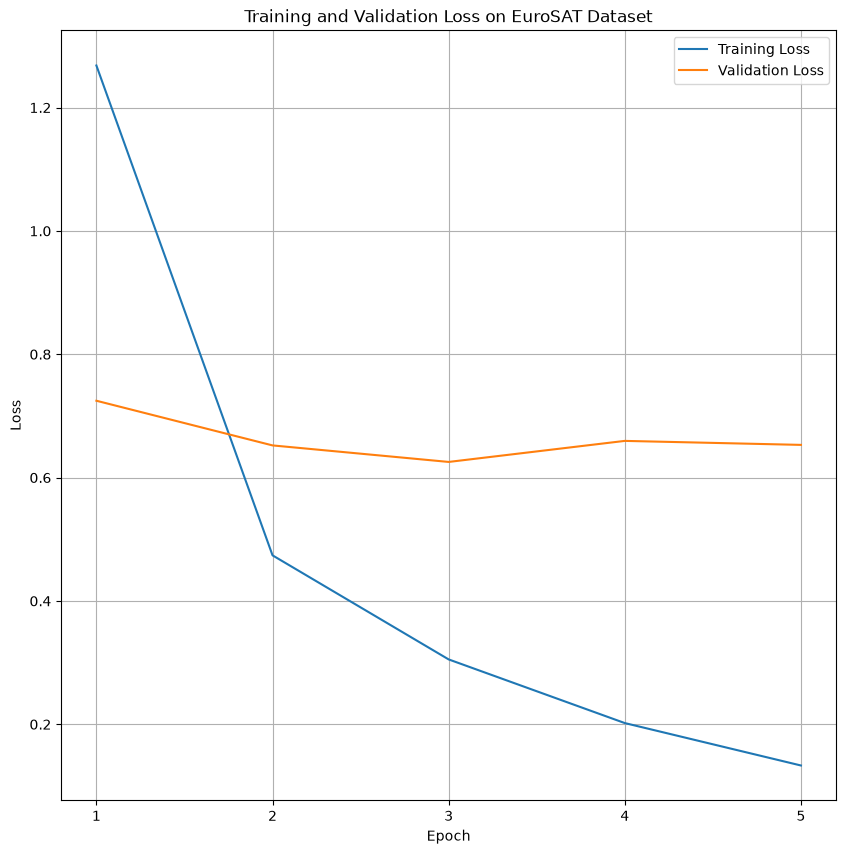

In [2]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

# set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# download EuroSAT dataset from Kaggle
path = kagglehub.dataset_download("apollo2506/eurosat-dataset")

# locate the RGB image folders
root = os.path.join(path, "EuroSAT")

if not os.path.isdir(root):
    raise FileNotFoundError(
        "EuroSAT folder not found"
    )

# get the 10 class names
class_names = sorted(
    d for d in os.listdir(root)
    if os.path.isdir(os.path.join(root, d))
)

print("Classes:", class_names)

if len(class_names) != 10:
    raise ValueError("Expected 10 EuroSAT classes")

# collect image paths from each class
class_files = []

for c in class_names:
    paths = sorted(glob.glob(os.path.join(root, c, "*.jpg")))

    if len(paths) < 250:
        raise ValueError(f"Not enough images in class {c}")

    class_files.append(paths)

# interleave 250 images per class to create balanced training and test subsets
files = [
    class_files[c][i]
    for i in range(250)
    for c in range(10)
]

labels = np.array([
    c
    for i in range(250)
    for c in range(10)
])

# load and normalize images
def load_images(paths):
    images = [
        tf.io.decode_jpeg(
            tf.io.read_file(p),
            channels=3
        ).numpy()
        for p in paths
    ]

    return np.stack(images).astype("float32") / 255.0

# select training and test subsets
X_train = load_images(files[:2000])
y_train = labels[:2000]

X_test = load_images(files[2000:2500])
y_test = labels[2000:2500]

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

# load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(64, 64, 3)
)

# freeze pretrained layers
base_model.trainable = False

# build classifier using frozen features
inputs = tf.keras.Input(shape=(64, 64, 3))

# scale inputs to [-1, 1]
x = tf.keras.layers.Rescaling(
    2.0,
    offset=-1.0
)(inputs)

# use pretrained network as feature extractor without updating weights
x = base_model(x, training=False)

# classification layers
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)

# probabilities for the 10 EuroSAT categories
outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

# configure Adam optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# compile model
model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# train model using 10% of training data for validation
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# evaluate on test data
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

# plot training and validation loss
plt.figure(figsize=(10, 10))

epochs = range(1, len(history.history["loss"]) + 1)

plt.plot(epochs, history.history["loss"], label="Training Loss")
plt.plot(epochs, history.history["val_loss"], label="Validation Loss")

plt.xticks(epochs)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss on EuroSAT Dataset")
plt.legend()
plt.grid(True)
plt.show()